## Cell 1 — Set up the modeling environment
This cell imports the libraries required to build and evaluate the classification models. The modeling notebook is kept separate from the EDA notebook so the experimental workflow remains reproducible and easy to follow.

In [1]:
import pandas as pd
import numpy as np
import json
import os

## Cell 2: Loading the required datasets
This cell loads the book metadata and book-to-category relationship table that will be used to construct the multi-label modeling dataset.

In [2]:
books = pd.read_json(
    "../data/RokomariBG_Dataset/book.json"
)

book_categories = pd.read_json(
    "../data/RokomariBG_Dataset/book_to_category.json"
)

## Cell 3: Build the multi-label target
This cell groups all category assignments belonging to each book into a list. The resulting structure allows each book to have one or more category labels.

In [3]:
labels = (
    book_categories
    .groupby("book_id")["category_id"]
    .apply(list)
    .reset_index()
)

labels.shape

(107680, 2)

## Cell 4: Create one representative record per book
The raw book table contains repeated `book_id` values. One row per book ID is retained for modeling so the same book is not duplicated as an independent observation.

In [4]:
books_unique = (
    books
    .drop_duplicates(subset="book_id", keep="first")
    .copy()
)

print("Unique books:", len(books_unique))

Unique books: 127302


## Cell 5: Merge book metadata with category labels
This cell joins the unique book records with their grouped category lists to create the initial modeling dataframe.

In [5]:
model1_df = books_unique.merge(
    labels,
    on="book_id",
    how="inner"
)

print("Model 1 rows:", len(model1_df))
print("Model 1 columns:", model1_df.shape[1])

Model 1 rows: 107680
Model 1 columns: 21


## Cell 6: Make the target column explicit
The grouped category-list column is renamed to `categories` so it is clearly identified as the multi-label target.

In [6]:
model1_df = model1_df.rename(
    columns={"category_id_y": "categories"}
)

model1_df[["book_id", "categories"]].head()

,book_id,categories
0,1,"[1392, 904]"
1,2,[678]
2,3,[678]
3,6,[678]
4,7,[678]


## Cell 7: Create the baseline text feature
The title and raw summary are combined into a single text input. For Model 1, preprocessing is intentionally minimal so it provides a genuine baseline.

In [7]:
model1_df["book_summary"] = (
    model1_df["book_summary"].fillna("")
)

model1_df["text"] = (
    model1_df["book_title"]
    + " "
    + model1_df["book_summary"]
)

print("Books:", len(model1_df))
print(
    "Empty summaries:",
    (model1_df["book_summary"].str.strip() == "").sum()
)

Books: 107680
Empty summaries: 35


## Cell 8: Select frequent categories
EDA showed a strong long-tail category distribution. We therefore retain categories with at least 100 books, giving a practical set of 478 frequent categories for the modeling experiments.

In [8]:
category_frequency = (
    book_categories
    .groupby("category_id")["book_id"]
    .nunique()
    .sort_values(ascending=False)
)

selected_categories = category_frequency[
    category_frequency >= 100
].index.tolist()

print("Selected categories:", len(selected_categories))

Selected categories: 478


## Cell 9: Restrict labels to the selected categories
Each book keeps only the selected frequent-category labels. Books with no remaining selected category are removed because they have no valid target for this classification task.

In [9]:
model1_df["categories"] = model1_df["categories"].apply(
    lambda cats: [c for c in cats if c in selected_categories]
)

model1_df = model1_df[
    model1_df["categories"].map(len) > 0
].copy()

print("Books remaining:", len(model1_df))

Books remaining: 102227


## Cell 10: Analysis step
This cell performs the corresponding data-preparation, modeling, evaluation, or result-recording step. The output is used directly by the following stage of the workflow.

In [10]:
model1_df["book_summary"] = model1_df["book_summary"].fillna("")

model1_df["text"] = (
    model1_df["book_title"] + " " +
    model1_df["book_summary"]
)

print("Books:", len(model1_df))
print("Categories:", len(selected_categories))

Books: 102227
Categories: 478


## Cell 11: Encode the multi-label target
`MultiLabelBinarizer` converts each book’s list of category IDs into a sparse multi-hot target matrix. Each column represents one of the selected categories.

In [11]:
from sklearn.preprocessing import MultiLabelBinarizer

X = model1_df["text"]

mlb = MultiLabelBinarizer(sparse_output=True)
y_bin = mlb.fit_transform(model1_df["categories"])

print("Categories:", len(mlb.classes_))
print("Target shape:", y_bin.shape)

Categories: 478
Target shape: (102227, 478)


## Cell 12: Create the train/validation/test split
The final modeling population is split into training, validation, and test sets using the same random seed. These split indices are reused across Models 1–3 to make comparisons fair.

In [12]:
from sklearn.model_selection import train_test_split
import numpy as np

indices = np.arange(len(model1_df))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 71558
Validation: 15334
Test: 15335


## Cell 13: Verify training-label coverage
This check confirms that every selected category has at least one training example, so the models are not asked to learn a category that is completely absent from training.

In [13]:
train_category_counts = np.asarray(
    y_bin[train_idx].sum(axis=0)
).ravel()

print(
    "Categories absent from training:",
    (train_category_counts == 0).sum()
)

Categories absent from training: 0


## Cell 14: Materialize the train, validation, and test data
The split indices are used to create the text and target arrays for each partition. These objects are reused throughout the modeling workflow.

In [14]:
X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
X_test = X.iloc[test_idx]

y_train = y_bin[train_idx]
y_val = y_bin[val_idx]
y_test = y_bin[test_idx]

print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.shape, y_val.shape, y_test.shape)

(71558,) (15334,) (15335,)
(71558, 478) (15334, 478) (15335, 478)


## Cell 15: Convert text to TF-IDF features
TF-IDF transforms the title-and-summary text into sparse numerical features using up to 30,000 unigrams and bigrams. The vectorizer is fitted only on training text and then applied to validation and test data.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Train TF-IDF:", X_train_tfidf.shape)
print("Validation TF-IDF:", X_val_tfidf.shape)
print("Test TF-IDF:", X_test_tfidf.shape)

Train TF-IDF: (71558, 30000)
Validation TF-IDF: (15334, 30000)
Test TF-IDF: (15335, 30000)


## Cell 16: Model 1 — baseline classifier
Model 1 uses TF-IDF text features with a One-vs-Rest ensemble of Logistic Regression classifiers. This establishes the baseline performance using raw text.

In [28]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

X_train_model = X_train_tfidf.tocsr(copy=True)

model1 = OneVsRestClassifier(
    LogisticRegression(
        max_iter=500,
        solver="liblinear"
    ),
    n_jobs=1
)

model1.fit(X_train_model, y_train)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegre...r='liblinear')
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",1
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
Name,Type,Value
"classes_ classes_: array, shape = [`n_classes`]Class labels.","ndarray[int64](478,)","[ 0, 1, 2,...,475,476,477]"
estimators_ estimators_: list of `n_classes` estimatorsEstimators used for predictions.,list,"[LogisticRegre...r='liblinear'), LogisticRegre...r='liblinear'), LogisticRegre...r='liblinear'), LogisticRegre...r='liblinear'), ...]"
label_binarizer_ label_binarizer_: LabelBinarizer objectObject used to transform multiclass labels to binary labels andvice-versa.,LabelBinarizer,LabelBinarize...e_output=True)
multilabel_ multilabel_: booleanWhether a OneVsRestClassifier is a multilabel classifier.,bool,True
n_classes_ n_classes_: intNumber of classes.,int,478
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,30000
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solver

## Cell 17: Save Model 1 artifacts
The trained Model 1, its TF-IDF vectorizer, and its label encoder are saved so the expensive training step does not need to be repeated.

In [29]:
import os
import joblib

os.makedirs("../results/models", exist_ok=True)

joblib.dump(
    model1,
    "../results/models/model1_logistic_regression.joblib"
)

joblib.dump(
    tfidf,
    "../results/models/model1_tfidf.joblib"
)

joblib.dump(
    mlb,
    "../results/models/model1_label_binarizer.joblib"
)

print("Model 1, TF-IDF, and label encoder saved successfully.")

Model 1, TF-IDF, and label encoder saved successfully.


## Cell 18: Reload Model 1 artifacts
The saved Model 1 components are loaded from disk so prediction and evaluation can be performed without retraining the classifier.

In [16]:
import joblib

model1 = joblib.load(
    "../results/models/model1_logistic_regression.joblib"
)

tfidf = joblib.load(
    "../results/models/model1_tfidf.joblib"
)

mlb = joblib.load(
    "../results/models/model1_label_binarizer.joblib"
)

print("Model 1 artifacts loaded successfully.")

Model 1 artifacts loaded successfully.


## Cell 19: Prepare Model 1 test features
The saved TF-IDF vectorizer transforms the test text using the vocabulary and IDF statistics learned from the training data.

In [17]:
X_test_tfidf = tfidf.transform(X_test)

print("Test TF-IDF shape:", X_test_tfidf.shape)

Test TF-IDF shape: (15335, 30000)


## Cell 20: Generate Model 1 predictions
The trained baseline classifier predicts a multi-label category vector for every test book.

In [18]:
y_pred = model1.predict(X_test_tfidf)

print("Prediction shape:", y_pred.shape)

Prediction shape: (15335, 478)


## Cell 21: Inspect Model 1 predictions
The predicted binary vectors are converted back into category IDs and a small sample is compared with the true labels for qualitative inspection.

In [19]:
predicted_categories = mlb.inverse_transform(y_pred)

print("Example predictions:")
for i in range(5):
    print(f"\nBook {i+1}")
    print("Actual:   ", mlb.inverse_transform(y_test[i:i+1])[0])
    print("Predicted:", predicted_categories[i])

Example predictions:

Book 1
Actual:    (np.int64(678),)
Predicted: ()

Book 2
Actual:    (np.int64(403),)
Predicted: ()

Book 3
Actual:    (np.int64(30),)
Predicted: ()

Book 4
Actual:    (np.int64(176),)
Predicted: (np.int64(176),)

Book 5
Actual:    (np.int64(364),)
Predicted: ()


## Cell 22: Evaluate Model 1
Precision, Recall, and F1-score are calculated using weighted averaging. These are the evaluation metrics used consistently for all three models.

In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Precision: 0.4044
Recall:    0.0612
F1-score:  0.0974


## Cell 23: Analysis step
This cell performs the corresponding data-preparation, modeling, evaluation, or result-recording step. The output is used directly by the following stage of the workflow.

In [21]:
print("Model 1 Results")
print("----------------")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nModel 1 observation:")
print(
    "The baseline model achieved moderate precision but very low recall, "
    "indicating that it predicts relatively few categories and misses many "
    "of the true labels."
)

Model 1 Results
----------------
Precision: 0.4044
Recall:    0.0612
F1-score:  0.0974

Model 1 observation:
The baseline model achieved moderate precision but very low recall, indicating that it predicts relatively few categories and misses many of the true labels.


## Cell 24: Save Model 1 results
The baseline Precision, Recall, and F1-score are stored in the shared model-comparison CSV for later comparison with Models 2 and 3.

In [25]:
import os

os.makedirs("../results", exist_ok=True)

model1_results = pd.DataFrame({
    "Model": ["Model 1 - Baseline"],
    "Precision": [precision],
    "Recall": [recall],
    "F1-score": [f1]
})

model1_results.to_csv(
    "../results/model_comparison.csv",
    index=False
)

model1_results

,Model,Precision,Recall,F1-score
0,Model 1 - Baseline,0.404387,0.061244,0.097359


## Cell 24: Model 2 — cleaned-text dataset
Model 2 uses the same books, target labels, and split as Model 1. The main experimental change is the cleaning of the summary text. 

In [22]:
model2_df = model1_df[
    ["book_id", "book_title", "book_summary", "categories"]
].copy()

print("Model 2 books:", len(model2_df))
print("Model 2 categories:", len(mlb.classes_))

Model 2 books: 102227
Model 2 categories: 478


## Cell 25: Clean summary text
The summary cleaner removes the `Show More` scraping artifact, simple HTML tags, and repeated whitespace while leaving the original raw summary available for comparison.

In [ ]:
import re

def clean_summary(text):
    if pd.isna(text):
        return ""

    text = str(text)

    text = re.sub(r"\bshow\s+more\b", " ", text, flags=re.IGNORECASE)

    text = re.sub(r"<[^>]+>", " ", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()


model2_df["clean_summary"] = (
    model2_df["book_summary"]
    .apply(clean_summary)
)

## Cell 26: Build the cleaned text feature
The cleaned summary is combined with the book title to create the text input used by Model 2.

In [24]:
model2_df["text"] = (
    model2_df["book_title"].fillna("").astype(str)
    + " "
    + model2_df["clean_summary"]
)

print(model2_df[[
    "book_title",
    "book_summary",
    "clean_summary",
    "text"
]].head())

         book_title                                       book_summary  \
0  সুশাসনের সন্ধানে  "সুশাসনের সন্ধানে" বইটির প্রথম ফ্ল্যাপ-এর লেখা...   
1        শেষেরকবিতা  ‘শেষের কবিতা’ বইয়ের কিছু অংশঃ অমিত-চরিত অমিত র...   
2          নৌকাডুবি  "নৌকাডুবি” বইয়ের ভূমিকার থেকে নেয়া: পাঠক যে ভা...   
3               ঘরে                                          Show More   
4           যোগাযোগ  "যোগাযোগ" বইটির ভূমিকা থেকে নেয়াঃ “ঘরে বাইরে” ...   

                                       clean_summary  \
0  "সুশাসনের সন্ধানে" বইটির প্রথম ফ্ল্যাপ-এর লেখা...   
1  ‘শেষের কবিতা’ বইয়ের কিছু অংশঃ অমিত-চরিত অমিত র...   
2  "নৌকাডুবি” বইয়ের ভূমিকার থেকে নেয়া: পাঠক যে ভা...   
3                                                      
4  "যোগাযোগ" বইটির ভূমিকা থেকে নেয়াঃ “ঘরে বাইরে” ...   

                                                text  
0  সুশাসনের সন্ধানে "সুশাসনের সন্ধানে" বইটির প্রথ...  
1  শেষেরকবিতা ‘শেষের কবিতা’ বইয়ের কিছু অংশঃ অমিত-...  
2  নৌকাডুবি "নৌকাডুবি” বইয়ের ভূমিকার থেকে নেয়া: প... 

## Cell 27: Build the cleaned text feature
The cleaned summary is combined with the book title to create the text input used by Model 2.

In [25]:
print(
    "Texts containing 'Show More':",
    model2_df["text"]
    .str.contains("Show More", case=False, regex=False)
    .sum()
)

print(
    "Empty cleaned summaries:",
    (model2_df["clean_summary"].str.strip() == "").sum()
)

Texts containing 'Show More': 0
Empty cleaned summaries: 58158


## Cell 28: Build the cleaned text feature
The cleaned summary is combined with the book title to create the text input used by Model 2.

In [26]:
X2 = model2_df["text"]

X2_train = X2.iloc[train_idx]
X2_val = X2.iloc[val_idx]
X2_test = X2.iloc[test_idx]

print("Train:", len(X2_train))
print("Validation:", len(X2_val))
print("Test:", len(X2_test))

Train: 71558
Validation: 15334
Test: 15335


## Cell 29: Convert text to TF-IDF features
TF-IDF transforms the title-and-summary text into sparse numerical features using up to 30,000 unigrams and bigrams. The vectorizer is fitted only on training text and then applied to validation and test data.

In [27]:
tfidf2 = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2
)

X2_train_tfidf = tfidf2.fit_transform(X2_train)
X2_val_tfidf = tfidf2.transform(X2_val)
X2_test_tfidf = tfidf2.transform(X2_test)

print("Training TF-IDF:", X2_train_tfidf.shape)
print("Validation TF-IDF:", X2_val_tfidf.shape)
print("Test TF-IDF:", X2_test_tfidf.shape)

Training TF-IDF: (71558, 30000)
Validation TF-IDF: (15334, 30000)
Test TF-IDF: (15335, 30000)


## Cell 30: Model 2 — cleaned-text classifier
Model 2 uses the same One-vs-Rest Logistic Regression configuration as Model 1, allowing us to test whether cleaning the text improves performance.

In [40]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

X2_train_model = X2_train_tfidf.tocsr(copy=True)

model2 = OneVsRestClassifier(
    LogisticRegression(
        max_iter=500,
        solver="liblinear"
    ),
    n_jobs=1
)

model2.fit(X2_train_model, y_train)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegre...r='liblinear')
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",1
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
Name,Type,Value
"classes_ classes_: array, shape = [`n_classes`]Class labels.","ndarray[int64](478,)","[ 0, 1, 2,...,475,476,477]"
estimators_ estimators_: list of `n_classes` estimatorsEstimators used for predictions.,list,"[LogisticRegre...r='liblinear'), LogisticRegre...r='liblinear'), LogisticRegre...r='liblinear'), LogisticRegre...r='liblinear'), ...]"
label_binarizer_ label_binarizer_: LabelBinarizer objectObject used to transform multiclass labels to binary labels andvice-versa.,LabelBinarizer,LabelBinarize...e_output=True)
multilabel_ multilabel_: booleanWhether a OneVsRestClassifier is a multilabel classifier.,bool,True
n_classes_ n_classes_: intNumber of classes.,int,478
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,30000
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solver

## Cell 31: Save Model 2 artifacts
The cleaned-text classifier and its TF-IDF vectorizer are saved for reproducibility and to avoid retraining.

In [41]:
import os
import joblib

os.makedirs("../results/models", exist_ok=True)

joblib.dump(
    model2,
    "../results/models/model2_logistic_regression.joblib"
)

joblib.dump(
    tfidf2,
    "../results/models/model2_tfidf.joblib"
)

print("Model 2 and TF-IDF saved successfully.")

Model 2 and TF-IDF saved successfully.


## Cell 32: Generate Model 2 predictions
The cleaned-text model predicts one or more categories for each test book.

In [28]:
y2_pred = model2.predict(X2_test_tfidf)

print("Prediction shape:", y2_pred.shape)

NameError: name 'model2' is not defined

## Cell 33: Inspect Model 2 predictions
A few Model 2 predictions are compared with the corresponding true category labels.

In [43]:
predicted_categories_2 = mlb.inverse_transform(y2_pred)

print("Example Model 2 predictions:")

for i in range(5):
    actual = mlb.inverse_transform(y_test[i:i+1])[0]
    
    print(f"\nBook {i+1}")
    print("Actual:   ", actual)
    print("Predicted:", predicted_categories_2[i])

Example Model 2 predictions:

Book 1
Actual:    (np.int64(678),)
Predicted: ()

Book 2
Actual:    (np.int64(403),)
Predicted: ()

Book 3
Actual:    (np.int64(30),)
Predicted: ()

Book 4
Actual:    (np.int64(176),)
Predicted: (np.int64(176),)

Book 5
Actual:    (np.int64(364),)
Predicted: ()


## Cell 34: Evaluate Model 2
Model 2 is evaluated with the same weighted Precision, Recall, and F1-score procedure used for Model 1.

In [44]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision2 = precision_score(
    y_test,
    y2_pred,
    average="weighted",
    zero_division=0
)

recall2 = recall_score(
    y_test,
    y2_pred,
    average="weighted",
    zero_division=0
)

f1_2 = f1_score(
    y_test,
    y2_pred,
    average="weighted",
    zero_division=0
)

print(f"Model 2 Precision: {precision2:.4f}")
print(f"Model 2 Recall:    {recall2:.4f}")
print(f"Model 2 F1-score:  {f1_2:.4f}")

Model 2 Precision: 0.3902
Model 2 Recall:    0.0595
Model 2 F1-score:  0.0947


## Cell 35: Saving Model 2 results
The Precision, Recall, and F1-score are stored in the shared model-comparison CSV for later comparison with Models 1 and 3.

In [45]:
model2_results = pd.DataFrame({
    "Model": ["Model 2 - Cleaned Text"],
    "Precision": [precision2],
    "Recall": [recall2],
    "F1-score": [f1_2]
})

comparison_path = "../results/model_comparison.csv"

if os.path.exists(comparison_path):
    existing_results = pd.read_csv(comparison_path)
    updated_results = pd.concat(
        [existing_results, model2_results],
        ignore_index=True
    )
else:
    updated_results = model2_results

updated_results.to_csv(
    comparison_path,
    index=False
)

updated_results

,Model,Precision,Recall,F1-score
0,Model 1 - Baseline,0.404387,0.061244,0.097359
1,Model 2 - Cleaned Text,0.390191,0.059525,0.094707


## Cell 36: Model 3 — text plus metadata
Model 3 starts from the cleaned text dataset and adds author and publisher IDs as metadata features.

In [29]:
model3_df = model2_df[
    ["book_id", "text", "categories"]
].copy()

model3_df = model3_df.merge(
    books_unique[
        ["book_id", "author_id", "publisher_id"]
    ],
    on="book_id",
    how="left"
)

print("Model 3 books:", len(model3_df))

Model 3 books: 102227


## Cell 37: Select reusable author and publisher values
Author and publisher frequencies are calculated within the modeling population. IDs appearing at least 10 times are retained as explicit metadata categories; rarer values are grouped later.

In [30]:
author_counts = model3_df["author_id"].value_counts()
publisher_counts = model3_df["publisher_id"].value_counts()

frequent_authors = author_counts[
    author_counts >= 10
].index

frequent_publishers = publisher_counts[
    publisher_counts >= 10
].index

print("Frequent authors:", len(frequent_authors))
print("Frequent publishers:", len(frequent_publishers))

Frequent authors: 1343
Frequent publishers: 1397


## Cell 38: Apply the same train/validation/test split to metadata
Author and publisher IDs are divided using the same split indices as the text features so every model is evaluated on the same books.

In [31]:
author_train = model3_df["author_id"].iloc[train_idx]
author_val = model3_df["author_id"].iloc[val_idx]
author_test = model3_df["author_id"].iloc[test_idx]

publisher_train = model3_df["publisher_id"].iloc[train_idx]
publisher_val = model3_df["publisher_id"].iloc[val_idx]
publisher_test = model3_df["publisher_id"].iloc[test_idx]

print("Train:", len(author_train))
print("Validation:", len(author_val))
print("Test:", len(author_test))

Train: 71558
Validation: 15334
Test: 15335


## Cell 39: Replacing rare meta data with group values
Filling in missing ublishers with `UNKNOWN` rather than dropping them.

In [32]:
def prepare_metadata(series, frequent_values, other_label):
    return (
        series
        .where(series.isin(frequent_values), other_label)
        .fillna("UNKNOWN")
        .astype(str)
    )

author_train = prepare_metadata(
    author_train, frequent_authors, "OTHER_AUTHOR"
)

author_val = prepare_metadata(
    author_val, frequent_authors, "OTHER_AUTHOR"
)

author_test = prepare_metadata(
    author_test, frequent_authors, "OTHER_AUTHOR"
)

publisher_train = prepare_metadata(
    publisher_train, frequent_publishers, "OTHER_PUBLISHER"
)

publisher_val = prepare_metadata(
    publisher_val, frequent_publishers, "OTHER_PUBLISHER"
)

publisher_test = prepare_metadata(
    publisher_test, frequent_publishers, "OTHER_PUBLISHER"
)

## Cell 40: Build metadata tables
Author and publisher values are combined into two-column metadata tables for each split before one-hot encoding.

In [33]:
metadata_train = pd.DataFrame({
    "author": author_train.values,
    "publisher": publisher_train.values
})

metadata_val = pd.DataFrame({
    "author": author_val.values,
    "publisher": publisher_val.values
})

metadata_test = pd.DataFrame({
    "author": author_test.values,
    "publisher": publisher_test.values
})

metadata_train.head()

,author,publisher
0,OTHER_AUTHOR,9628.0
1,OTHER_AUTHOR,872.0
2,OTHER_AUTHOR,4468.0
3,930,211.0
4,58719,10684.0


## Cell 41: One-hot encode metadata
The metadata encoder is fitted on training data only and then applied to validation and test data. `handle_unknown="ignore"` prevents unseen test-time categories from causing errors.

In [34]:
from sklearn.preprocessing import OneHotEncoder

metadata_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

metadata_train_matrix = metadata_encoder.fit_transform(
    metadata_train
)

metadata_val_matrix = metadata_encoder.transform(
    metadata_val
)

metadata_test_matrix = metadata_encoder.transform(
    metadata_test
)

print("Metadata train shape:", metadata_train_matrix.shape)
print("Metadata validation shape:", metadata_val_matrix.shape)
print("Metadata test shape:", metadata_test_matrix.shape)

Metadata train shape: (71558, 2742)
Metadata validation shape: (15334, 2742)
Metadata test shape: (15335, 2742)


## Cell 42: Combine text and metadata features
The 30,000 cleaned-text TF-IDF features are horizontally combined with the 2,742 one-hot metadata features to produce the final Model 3 feature matrix.

In [35]:
from scipy.sparse import hstack

X3_train = hstack([
    X2_train_tfidf,
    metadata_train_matrix
]).tocsr()

X3_val = hstack([
    X2_val_tfidf,
    metadata_val_matrix
]).tocsr()

X3_test = hstack([
    X2_test_tfidf,
    metadata_test_matrix
]).tocsr()

print("Model 3 training shape:", X3_train.shape)
print("Model 3 validation shape:", X3_val.shape)
print("Model 3 test shape:", X3_test.shape)

Model 3 training shape: (71558, 32742)
Model 3 validation shape: (15334, 32742)
Model 3 test shape: (15335, 32742)


## Cell 43: Model 3 — text plus metadata classifier
Model 3 uses the same One-vs-Rest Logistic Regression architecture as the baselines, but now learns from cleaned text together with selected author and publisher metadata.

In [36]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

model3 = OneVsRestClassifier(
    LogisticRegression(
        max_iter=500,
        solver="liblinear"
    ),
    n_jobs=1
)

model3.fit(X3_train, y_train)

print("Model 3 training completed successfully.")

Model 3 training completed successfully.


## Cell 43: Save Model 3 artifacts
The final classifier and metadata encoder are saved so the best-performing model can be reused without retraining.

In [37]:
import joblib
import os

os.makedirs("../results/models", exist_ok=True)

joblib.dump(
    model3,
    "../results/models/model3_logistic_regression.joblib"
)

joblib.dump(
    metadata_encoder,
    "../results/models/model3_metadata_encoder.joblib"
)

print("Model 3 and metadata encoder saved successfully.")

Model 3 and metadata encoder saved successfully.


## Cell 44: Generate Model 3 predictions
The final model produces multi-label predictions for the test set.

In [38]:
y3_pred = model3.predict(X3_test)

print("Prediction shape:", y3_pred.shape)

Prediction shape: (15335, 478)


## Cell 45: Inspect Model 3 predictions
A sample of final predictions is compared with the true category labels to interpret model behavior.

In [39]:
predicted_categories_3 = mlb.inverse_transform(y3_pred)

print("Example Model 3 predictions:")

for i in range(5):
    actual = mlb.inverse_transform(y_test[i:i+1])[0]

    print(f"\nBook {i+1}")
    print("Actual:   ", actual)
    print("Predicted:", predicted_categories_3[i])

Example Model 3 predictions:

Book 1
Actual:    (np.int64(678),)
Predicted: ()

Book 2
Actual:    (np.int64(403),)
Predicted: ()

Book 3
Actual:    (np.int64(30),)
Predicted: ()

Book 4
Actual:    (np.int64(176),)
Predicted: (np.int64(176),)

Book 5
Actual:    (np.int64(364),)
Predicted: ()


## Cell 46: Evaluate Model 3
Model 3 is evaluated with the same weighted Precision, Recall, and F1-score procedure used for Models 1 and 2.

In [40]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision3 = precision_score(
    y_test,
    y3_pred,
    average="weighted",
    zero_division=0
)

recall3 = recall_score(
    y_test,
    y3_pred,
    average="weighted",
    zero_division=0
)

f1_3 = f1_score(
    y_test,
    y3_pred,
    average="weighted",
    zero_division=0
)

print(f"Model 3 Precision: {precision3:.4f}")
print(f"Model 3 Recall:    {recall3:.4f}")
print(f"Model 3 F1-score:  {f1_3:.4f}")

Model 3 Precision: 0.6518
Model 3 Recall:    0.1491
Model 3 F1-score:  0.2226


## Cell 47: Saving Model 3
The baseline Precision, Recall, and F1-score are stored in the shared model-comparison CSV for later comparison with Models 1 and 2.

In [41]:
model3_results = pd.DataFrame({
    "Model": ["Model 3 - Cleaned Text + Metadata"],
    "Precision": [precision3],
    "Recall": [recall3],
    "F1-score": [f1_3]
})

comparison_path = "../results/model_comparison.csv"

existing_results = pd.read_csv(comparison_path)

updated_results = pd.concat(
    [existing_results, model3_results],
    ignore_index=True
)

updated_results.to_csv(
    comparison_path,
    index=False
)

updated_results

,Model,Precision,Recall,F1-score
0,Model 1 - Baseline,0.404387,0.061244,0.097359
1,Model 2 - Cleaned Text,0.390191,0.059525,0.094707
2,Model 3 - Cleaned Text + Metadata,0.651819,0.149083,0.222593


## Cell 48: Compare the three models visually
This cell creates the report-ready comparison figure for Precision, Recall, and F1-score across Models 1–3 and saves it to the results folder.

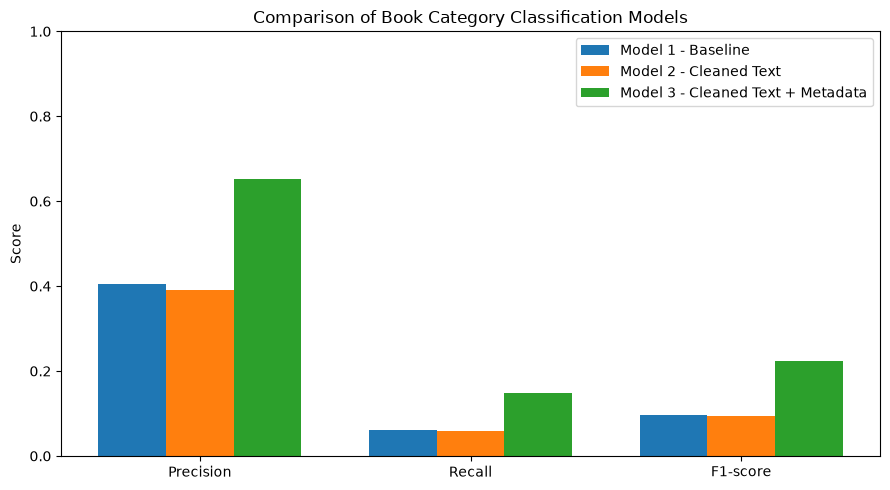

In [42]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Precision", "Recall", "F1-score"]

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))

for i, row in updated_results.iterrows():
    values = [
        row["Precision"],
        row["Recall"],
        row["F1-score"]
    ]

    ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=row["Model"]
    )

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score")
ax.set_title("Comparison of Book Category Classification Models")
ax.legend()
ax.set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "../results/figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()